# ⌨️ Autocomplete & Autocorrect — NLP Analytics on a Project Gutenberg Corpus

**Objective:** implement and compare several approaches for **text prediction (autocomplete)** and **spelling correction (autocorrect)** on a real text corpus, and measure their accuracy *and* efficiency.

**Corpus:** *Alice's Adventures in Wonderland* (Project Gutenberg eBook #11).

| Component | Approaches compared |
|---|---|
| **Autocomplete** | Unigram (most-frequent words) · Bigram · Trigram with back-off — all frequency based |
| **Autocorrect** | Levenshtein distance · Damerau-Levenshtein distance · Norvig-style edit candidates (· `pyspellchecker` if installed) |

**Outline**
1. Load the corpus
2. NLP preprocessing (tokenisation, lower-casing, punctuation and stop-word removal)
3. Word-frequency analysis (top 20 words)
4. Autocomplete: implementation, 10+ test prefixes, evaluation
5. Autocorrect: implementation, 20+ misspellings, evaluation, confusion matrices
6. Performance metrics: definitions of precision and recall
7. Algorithm comparison (accuracy and efficiency)
8. Discussion: limitations vs production keyboards

> **How to run:** keep `The_Project_Gutenberg.csv` next to this notebook (or in `data/`), `pip install -r req_nlp.txt`, then *Kernel → Restart & Run All*. It takes about two minutes. NLTK stop-words are downloaded automatically if internet is available; otherwise a built-in copy of the same list is used.

In [3]:
import re
import time
import random
import string
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:          # lets the same code run as a plain script
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# ───────────────────────────── CONFIGURATION ─────────────────────────────
CORPUS_PATHS     = ["The_Project_Gutenberg.csv"]   # add more plain-text books here to enlarge the corpus
RANDOM_STATE     = 42
TEST_FRACTION    = 0.20     # share of sentences held out to evaluate autocomplete
TOP_K            = 3        # number of suggestions shown to the user
MAX_EDIT_DISTANCE = 2       # autocorrect gives up beyond this many edits
N_TYPOS_PER_KIND = 250      # synthetic misspellings per error type (x4 types)
N_CORRECT_WORDS  = 1000     # correctly spelled words added to the autocorrect test (to measure false corrections)
rng = random.Random(RANDOM_STATE)

## 1. Load the corpus

The file is named `.csv`, but it is **not a table**: it is the plain text of the book (the first line is the Project Gutenberg title line, and commas appear inside sentences), so `pd.read_csv` fails on it. It is therefore read as text, the Gutenberg licence header and footer are stripped, the table of contents is skipped, and the result is stored in a pandas DataFrame with one row per paragraph.

In [4]:
def strip_gutenberg(text):
    # keep only the book itself: drop the licence header/footer and the table of contents
    start = re.search(r"\*\*\* START OF[^\n]*\n", text)
    end = re.search(r"\*\*\* END OF", text)
    if start and end:
        text = text[start.end():end.start()]
    body = re.search(r"^CHAPTER I\.\s*$", text, flags=re.M)   # first real chapter heading (the contents list is indented)
    return text[body.start():] if body else text

def load_corpus(paths=CORPUS_PATHS):
    rows = []
    for path in paths:
        p = next((c for c in (Path(path), Path("data") / path) if c.exists()), None)
        if p is None:
            raise FileNotFoundError(f"Could not find '{path}' next to the notebook or in ./data/")
        text = p.read_text(encoding="utf-8-sig", errors="replace").replace("\r\n", "\n").replace("\r", "\n")
        chapter = 0
        for par in re.split(r"\n\s*\n", strip_gutenberg(text)):
            par = " ".join(par.split())
            par = re.sub(r"\[Illustration[^\]]*\]", "", par).strip()
            if not re.search(r"[A-Za-z]", par) or par == "THE END":
                continue                                    # blank lines, '* * *' separators
            if re.match(r"^CHAPTER [IVXLC]+\.", par):
                chapter += 1                                # chapter heading: count it, do not keep it as text
                continue
            rows.append({"source": p.stem, "chapter": chapter, "text": par})
    frame = pd.DataFrame(rows)
    frame["n_words"] = frame["text"].str.split().str.len()
    return frame

paragraphs = load_corpus()
print(f"{len(paragraphs):,} paragraphs | {paragraphs['n_words'].sum():,} raw words | {paragraphs['chapter'].nunique()} chapters")
display(paragraphs.head(3))

789 paragraphs | 26,309 raw words | 12 chapters


,source,chapter,text,n_words
0,The_Project_Gutenberg,1,Alice was beginning to get very tired of sitti...,57
1,The_Project_Gutenberg,1,So she was considering in her own mind (as wel...,55
2,The_Project_Gutenberg,1,There was nothing so _very_ remarkable in that...,141


## 2. NLP preprocessing

Pipeline applied to every paragraph:

1. **Normalise**: curly quotes and apostrophes (`’ “ ”`) become plain ASCII, the Gutenberg italics markers (`_word_`) are removed, and dashes (`—`) become spaces so that `distance—but` is not glued into one word.
2. **Sentence split** on `. ! ?` (the unit used for n-grams, so a prediction never crosses a sentence boundary).
3. **Lower-case** everything.
4. **Tokenise** with a regular expression that keeps only letters and *inner* apostrophes, which removes punctuation but keeps contractions such as `don't` and `alice's`.
5. **Stop-word removal**, using the NLTK English list. Two token views are kept on purpose:
   - the **full** token stream (stop-words kept) is used for autocomplete and autocorrect, because next-word prediction must be able to suggest *the*, *of*, *and* (the most common words people type) and a spelling dictionary must contain them;
   - the **content-word** view (stop-words removed) is used for frequency analysis, where function words would drown out everything else.

In [5]:
FALLBACK_STOPWORDS = set("""i me my myself we our ours ourselves you you're you've you'll you'd your yours yourself yourselves
he him his himself she she's her hers herself it it's its itself they them their theirs themselves what which who whom this that
that'll these those am is are was were be been being have has had having do does did doing a an the and but if or because as until
while of at by for with about against between into through during before after above below to from up down in out on off over under
again further then once here there when where why how all any both each few more most other some such no nor not only own same so
than too very s t can will just don don't should should've now d ll m o re ve y ain aren aren't couldn couldn't didn didn't doesn
doesn't hadn hadn't hasn hasn't haven haven't isn isn't ma mightn mightn't mustn mustn't needn needn't shan shan't shouldn
shouldn't wasn wasn't weren weren't won won't wouldn wouldn't""".split())

def load_stopwords():
    try:
        import nltk
        from nltk.corpus import stopwords
        try:
            return set(stopwords.words("english")), "NLTK"
        except LookupError:
            nltk.download("stopwords", quiet=True)
            return set(stopwords.words("english")), "NLTK (downloaded)"
    except Exception:
        return FALLBACK_STOPWORDS, "built-in copy of the NLTK list (NLTK or its data not available)"

STOPWORDS, stop_source = load_stopwords()
print(f"Stop-word list: {len(STOPWORDS)} words from {stop_source}")

def normalise(text):
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = text.replace("_", "")
    return re.sub(r"[—–]|--", " ", text)

def split_sentences(paragraph):
    return [s for s in re.split(r"(?<=[.!?])[\"']*\s+", normalise(paragraph)) if s.strip()]

def tokenize(text):
    # lower-case, keep letters and inner apostrophes only (drops punctuation and digits)
    return re.findall(r"[a-z]+(?:'[a-z]+)*", normalise(text).lower())

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]

Stop-word list: 179 words from built-in copy of the NLTK list (NLTK or its data not available)


[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


In [6]:
# walk one real sentence through every step
example = split_sentences(paragraphs.loc[0, "text"])[0]
steps = pd.DataFrame({"step": ["1. original sentence", "2. lower-cased", "3. punctuation removed + tokenised", "4. stop-words removed"],
                      "result": [example, example.lower(), tokenize(example), remove_stopwords(tokenize(example))]})
pd.set_option("display.max_colwidth", 200)
display(steps)

,step,result
0,1. original sentence,"Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures o..."
1,2. lower-cased,"alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures o..."
2,3. punctuation removed + tokenised,"[alice, was, beginning, to, get, very, tired, of, sitting, by, her, sister, on, the, bank, and, of, having, nothing, to, do, once, or, twice, she, had, peeped, into, the, book, her, sister, was, r..."
3,4. stop-words removed,"[alice, beginning, get, tired, sitting, sister, bank, nothing, twice, peeped, book, sister, reading, pictures, conversations, use, book, thought, alice, without, pictures, conversations]"


In [7]:
sentences = []                                   # list of token lists (stop-words kept)
for par in paragraphs["text"]:
    for sent in split_sentences(par):
        toks = tokenize(sent)
        if len(toks) >= 2:
            sentences.append(toks)

all_tokens = [t for s in sentences for t in s]
content_tokens = remove_stopwords(all_tokens)
word_counts = Counter(all_tokens)
content_counts = Counter(content_tokens)

summary = pd.Series({
    "sentences": len(sentences),
    "tokens (all)": len(all_tokens),
    "tokens after stop-word removal": len(content_tokens),
    "share removed as stop-words": f"{1 - len(content_tokens) / len(all_tokens):.1%}",
    "vocabulary (unique words)": len(word_counts),
    "words seen only once (hapax)": sum(1 for c in word_counts.values() if c == 1),
    "average sentence length (tokens)": round(len(all_tokens) / len(sentences), 1),
}, name="corpus statistics")
display(summary.to_frame())

,corpus statistics
sentences,1630
tokens (all),26571
tokens after stop-word removal,12428
share removed as stop-words,53.2%
vocabulary (unique words),2610
words seen only once (hapax),1131
average sentence length (tokens),16.3


## 3. Word-frequency analysis: top 20 most frequent words

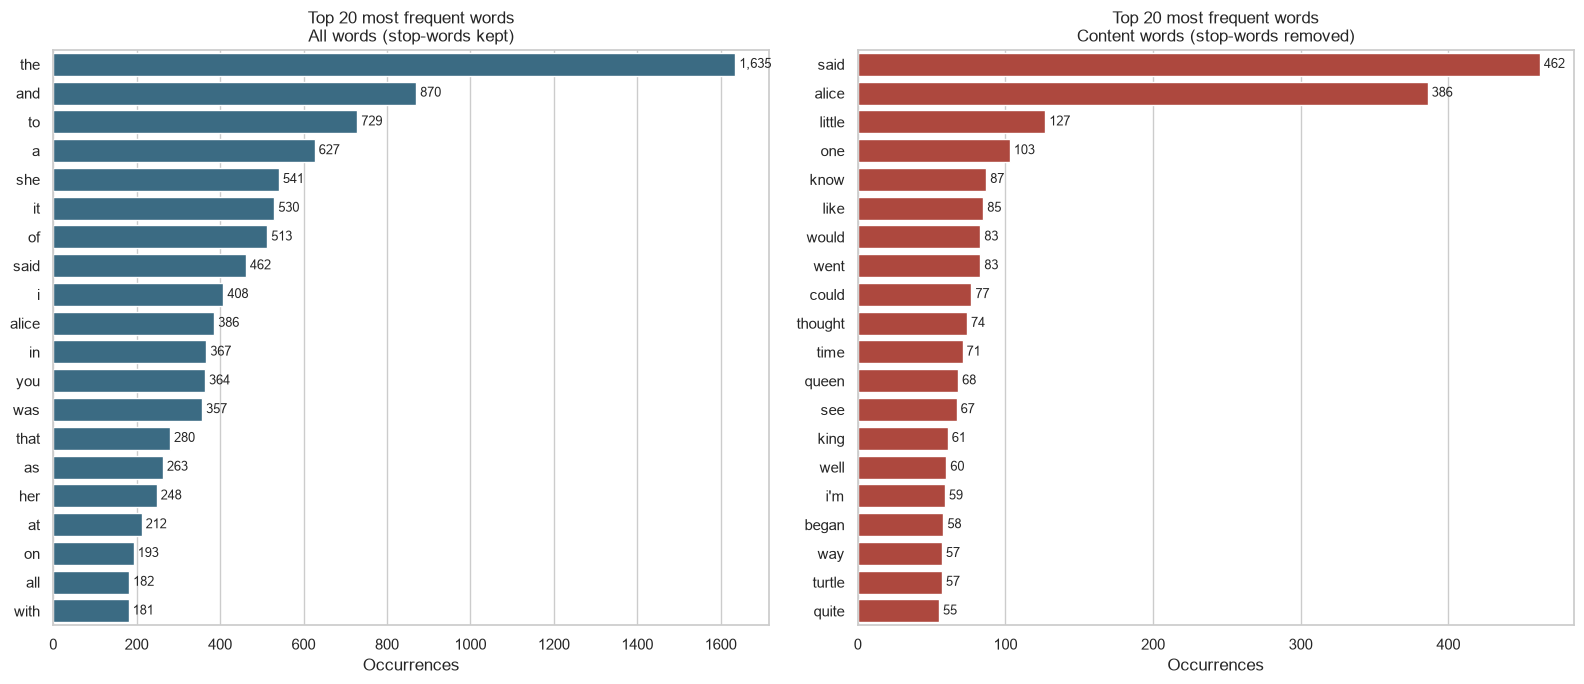

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, counts, title, color in [(axes[0], word_counts, "All words (stop-words kept)", "#2f6f8f"),
                                 (axes[1], content_counts, "Content words (stop-words removed)", "#c0392b")]:
    top = pd.DataFrame(counts.most_common(20), columns=["word", "count"])
    sns.barplot(data=top, y="word", x="count", color=color, ax=ax)
    for i, v in enumerate(top["count"]):
        ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    ax.set_title(f"Top 20 most frequent words\n{title}"); ax.set_xlabel("Occurrences"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**What the frequency analysis shows**
- With stop-words kept, the top 20 is almost entirely function words: *the* alone accounts for about 6% of all 26,571 tokens (1,635 occurrences), followed by *and*, *to*, *a*. Only *said* and *alice* are content words that make the cut.
- About **53% of all tokens are stop-words**. Removing them exposes what the book is about: *said* (462) and *alice* (386) dominate, followed by *little*, *one*, *know*, *queen*, *king* and *turtle*, which reflects a dialogue-heavy story with a small cast.
- The distribution is heavy-tailed (Zipf-like): of 2,610 distinct words, **1,131 (43%) occur only once**. That matters for both tasks: it limits how much an n-gram model can learn, and a dictionary built from this text will miss many ordinary words.
- Stop-word lists are not perfect: contractions such as *i'm* (59 occurrences) are not in the NLTK list and slip through as "content" words.

## 4. Autocomplete: frequency-based n-gram models

**Idea.** Count how often every word follows every context in the training text, then suggest the most frequent followers of what the user has typed so far.

| Model | Context used | Behaviour |
|---|---|---|
| **Unigram** | none | always suggests the globally most frequent words (a naive baseline) |
| **Bigram** | previous 1 word | suggests the words that most often follow the last word |
| **Trigram + back-off** | previous 2 words | uses the trigram counts first; if there are fewer than 3 suggestions it falls back to the bigram, then the unigram list ("stupid back-off") |

Every model also supports **completing a partly typed word**: given `the whi` it only offers words that start with `whi`, ranked by the same counts.

Sentence starts are padded with `<s>` so the first word of a sentence also has a context. The models are trained on **80% of the sentences**; the other 20% is held out for evaluation, so the scores measure prediction of text the model has never seen.

In [9]:
class NgramAutocomplete:
    # order = 1 (unigram), 2 (bigram) or 3 (trigram with back-off to lower orders)
    def __init__(self, order):
        self.order = order
        self.name = {1: "Unigram", 2: "Bigram", 3: "Trigram + back-off"}[order]

    def fit(self, sentences):
        t0 = time.perf_counter()
        counts = {n: defaultdict(Counter) for n in range(1, self.order + 1)}
        pad = ["<s>"] * (self.order - 1)
        for sent in sentences:
            seq = pad + sent
            for i in range(self.order - 1, len(seq)):
                for n in range(1, self.order + 1):
                    context = tuple(seq[i - n + 1:i])            # the n-1 words before position i
                    counts[n][context][seq[i]] += 1
        # rank followers once (count desc, then alphabetical so results are deterministic)
        self.ranked = {n: {ctx: [w for w, _ in sorted(c.items(), key=lambda kv: (-kv[1], kv[0]))]
                           for ctx, c in table.items()} for n, table in counts.items()}
        self.vocab = set(self.ranked[1][()])
        self.n_entries = sum(len(c) for table in counts.values() for c in table.values())   # stored (context, word) pairs
        self.fit_seconds = time.perf_counter() - t0
        return self

    def suggest(self, context, k=TOP_K, partial=""):
        # context: list of previous tokens; partial: the characters of the word being typed (may be empty)
        padded = ["<s>"] * (self.order - 1) + list(context)
        out, seen = [], set()
        for n in range(self.order, 0, -1):                           # longest context first, then back off
            ctx = tuple(padded[len(padded) - (n - 1):]) if n > 1 else ()
            for w in self.ranked[n].get(ctx, ()):
                if w not in seen and w != "<s>" and w.startswith(partial):
                    out.append(w); seen.add(w)
                    if len(out) == k:
                        return out
        return out

def autocomplete(model, text, k=TOP_K):
    # user-facing helper: 'the whi' -> completes the partial word; 'the white ' (trailing space) -> predicts the next word
    tokens = tokenize(text)
    if text and not text[-1].isspace() and tokens:
        return model.suggest(tokens[:-1], k, partial=tokens[-1])
    return model.suggest(tokens, k)

In [10]:
order_idx = list(range(len(sentences)))
random.Random(RANDOM_STATE).shuffle(order_idx)
n_test = int(len(order_idx) * TEST_FRACTION)
test_sents  = [sentences[i] for i in order_idx[:n_test]]
train_sents = [sentences[i] for i in order_idx[n_test:]]
print(f"Training sentences: {len(train_sents):,} | held-out test sentences: {len(test_sents):,}")

ac_models = {m.name: m.fit(train_sents) for m in (NgramAutocomplete(1), NgramAutocomplete(2), NgramAutocomplete(3))}
display(pd.DataFrame({"fit time (s)": {k: m.fit_seconds for k, m in ac_models.items()},
                      "stored n-gram entries": {k: m.n_entries for k, m in ac_models.items()}}).round(3))

Training sentences: 1,304 | held-out test sentences: 326


,fit time (s),stored n-gram entries
Unigram,0.012,2347
Bigram,0.032,13883
Trigram + back-off,0.163,31174


### 4.1 Demo: top-3 predictions for 12 input prefixes

In [11]:
prefixes = ["alice was ", "the white ", "said the ", "off with ", "down the ", "i don't ", "what a ",
            "she went ", "in a ", "how do ", "the queen ", "i shall "]

demo = []
for p in prefixes:
    row = {"prefix": p.rstrip() + " …"}
    for name, m in ac_models.items():
        row[name] = ", ".join(autocomplete(m, p)) or "—"
    demo.append(row)
display(pd.DataFrame(demo).set_index("prefix"))

,Unigram,Bigram,Trigram + back-off
prefix,,,
alice was …,"the, and, to","a, the, going","beginning, very, a"
the white …,"the, and, to","rabbit, kid, and","rabbit, kid, and"
said the …,"the, and, to","queen, king, gryphon","king, mock, caterpillar"
off with …,"the, and, to","the, a, one","his, her, their"
down the …,"the, and, to","queen, king, gryphon","chimney, king, bottle"
i don't …,"the, and, to","know, be, like","know, think, believe"
what a …,"the, and, to","little, very, large","curious, pity, clear"
she went …,"the, and, to","on, to, in","on, in, hunting"
in a …,"the, and, to","little, very, large","very, low, great"


### 4.2 Demo: completing a word that is still being typed

In [12]:
partials = ["the whi", "said the ma", "alice was be", "she c", "down the r", "what a cur"]
demo = []
for p in partials:
    row = {"typed so far": p}
    for name, m in ac_models.items():
        row[name] = ", ".join(autocomplete(m, p)) or "—"
    demo.append(row)
display(pd.DataFrame(demo).set_index("typed so far"))

,Unigram,Bigram,Trigram + back-off
typed so far,,,
the whi,"which, white, while","white, whiting, while","white, whiting, while"
said the ma,"march, made, make","march, matter, master","march, matter, master"
alice was be,"be, began, been","beginning, beating, be","beginning, beating, be"
she c,"could, come, can","could, came, carried","can't, carried, could"
down the r,"round, rabbit, right","rabbit, right, rest","rabbit, right, rest"
what a cur,"curious, curiosity, curiouser","curious, curiosity, curiouser","curious, curiosity, curiouser"


### 4.3 Evaluation on held-out text

Every word position in the held-out sentences is turned into a query: *context = the words before it, target = the word that actually came next*. The model returns its top 3 suggestions.

- **Hit@1 / Hit@3**: the real next word is the first suggestion / among the 3 suggestions.
- **Recall@3** = queries where the real word was among the 3 suggestions ÷ all queries (there is exactly one correct word per query, so this equals Hit@3).
- **Precision@3** = correct suggestions shown ÷ **all suggestions shown**. With one correct word, at most 1 of the 3 suggestions can be right, so Precision@3 can never exceed 33%; it is mainly useful for comparing models.
- **Coverage** = share of queries where the model could offer at least one suggestion.
- **Hit@3 with 2 letters typed**: the same test, but the user has already typed the first two letters of the target word (only for words longer than 2 letters).
- **Efficiency**: training time, number of stored n-grams (memory proxy) and average time per query.

Words that never appear in the training text (out-of-vocabulary) can never be suggested, which is counted as a miss.

In [13]:
def build_queries(sents, order=3):
    pad = ["<s>"] * (order - 1)
    queries = []
    for sent in sents:
        seq = pad + sent
        for i in range(order - 1, len(seq)):
            queries.append((seq[:i], seq[i]))
    return queries

queries = build_queries(test_sents)
queries_partial = [(c, t) for c, t in queries if len(t) > 2]
train_vocab = ac_models["Unigram"].vocab
oov_rate = np.mean([t not in train_vocab for _, t in queries])
print(f"{len(queries):,} test queries | {oov_rate:.1%} of target words never occur in the training text")

def evaluate_autocomplete(model, queries, queries_partial, k=TOP_K):
    hit1 = hitk = shown = covered = 0
    t0 = time.perf_counter()
    for ctx, target in queries:
        sug = model.suggest(ctx, k)
        shown += len(sug); covered += bool(sug)
        hit1 += bool(sug) and sug[0] == target
        hitk += target in sug
    micros = (time.perf_counter() - t0) / len(queries) * 1e6
    hit_partial = sum(t in model.suggest(c, k, partial=t[:2]) for c, t in queries_partial)
    return {"Hit@1": hit1 / len(queries), "Hit@3 (= Recall@3)": hitk / len(queries),
            "Precision@3": hitk / shown if shown else 0.0, "Coverage": covered / len(queries),
            "Hit@3 with 2 letters typed": hit_partial / len(queries_partial),
            "Fit time (s)": model.fit_seconds, "Stored n-grams": model.n_entries, "Time per query (µs)": micros}

ac_results = pd.DataFrame({name: evaluate_autocomplete(m, queries, queries_partial) for name, m in ac_models.items()}).T
ac_results.index.name = "Model"
display(ac_results.round(3))

5,316 test queries | 5.4% of target words never occur in the training text


,Hit@1,Hit@3 (= Recall@3),Precision@3,Coverage,Hit@3 with 2 letters typed,Fit time (s),Stored n-grams,Time per query (µs)
Model,,,,,,,,
Unigram,0.060,0.122,0.041,1.0,0.665,0.012,2347.0,1.786
Bigram,0.146,0.258,0.086,1.0,0.754,0.032,13883.0,2.169
Trigram + back-off,0.160,0.280,0.093,1.0,0.757,0.163,31174.0,2.503


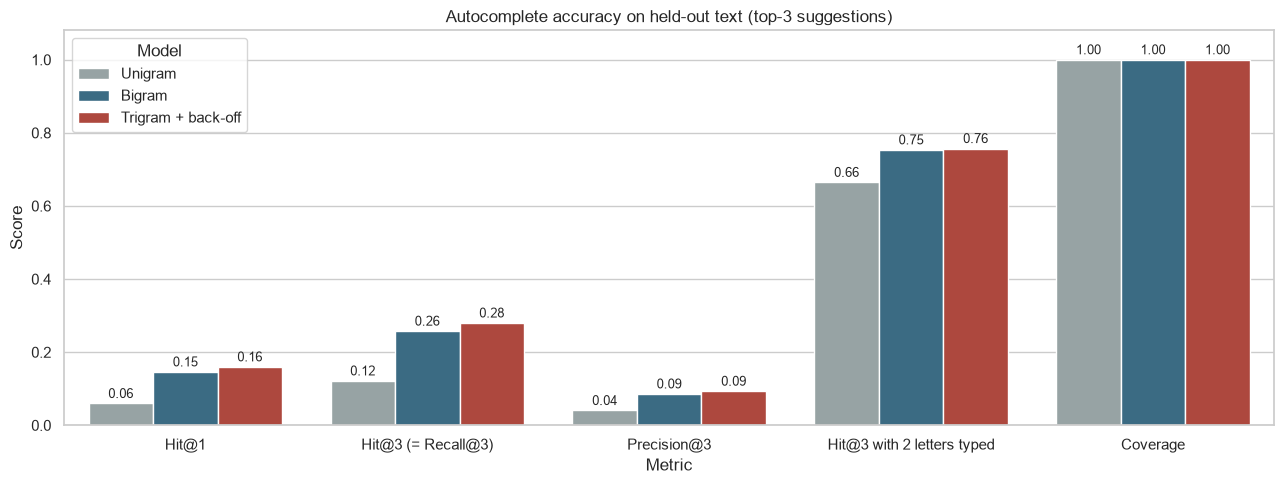

In [14]:
metrics = ["Hit@1", "Hit@3 (= Recall@3)", "Precision@3", "Hit@3 with 2 letters typed", "Coverage"]
plot_df = ac_results[metrics].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette=["#95a5a6", "#2f6f8f", "#c0392b"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, 1.08); ax.set_title("Autocomplete accuracy on held-out text (top-3 suggestions)")
plt.tight_layout(); plt.show()

**Reading the results** (5,316 held-out queries; 5.4% of the target words never occur in the training text and so can never be predicted)

- **Context roughly doubles the accuracy.** The unigram baseline has a Hit@3 of 12.2% (it always offers *the, and, to*), the bigram reaches **25.8%** and the trigram with back-off **28.0%**. Hit@1 goes from 6.0% to 14.6% to 16.0%.
- **The trigram adds only a little over the bigram** (+2.2 points of Hit@3) while storing about 2.2 times as many n-grams (31,174 vs 13,883). With only ~21,000 training tokens, most trigrams occur once, so the counts carry little evidence. Larger corpora and smoothing (e.g. Kneser-Ney) are what make higher orders pay off.
- **Absolute accuracy is modest, and that is expected.** Many words can legitimately follow any given context, so even a strong model rarely names the one word the author chose. Precision@3 is capped at 33.3% (only one of the three suggestions can be right) and the models reach 4–9%.
- **Typed letters matter more than context.** Once the user has typed the first two letters of the word, even the context-free unigram finds it in its top 3 in **66.5%** of cases and the bigram/trigram in **75–76%**. Context helps most at the very start of a word, when nothing has been typed yet.
- **Coverage is 100% for every model** because they all back off to the global word list when the context was never seen, so it does not separate the models here.
- **Efficiency is not a differentiator at this scale:** training takes 0.01–0.1 s and a query takes about 1–2 microseconds, because suggestion lists are ranked once at training time and a query is just a dictionary lookup.
- Qualitatively the demo tables look sensible: `the white` → *rabbit*, `i don't` → *know, think, believe*, `said the` → *king, mock, caterpillar*, and partial words are completed in context (`the whi` → *white, whiting, while* for the trigram).

## 5. Autocorrect: edit-distance spelling correction

**Idea.** A word that is not in the dictionary is probably a typo. Replace it with the dictionary word that needs the fewest single-character edits, and break ties with the word's frequency in the corpus (more common words are more likely to be what was meant). If nothing is within `MAX_EDIT_DISTANCE` edits, the word is left unchanged. Words that are already in the dictionary are never touched.

The dictionary is every word of the **training sentences** (the same 80% used for autocomplete) with its frequency. The misspellings are made from dictionary words, so the test measures whether the *error correction* finds the right entry; the correctly spelled words are taken from the **held-out 20%**, which contain words the dictionary has never seen. That is realistic (a spell-checker always meets words missing from its dictionary) and it is what exposes false corrections.

| Approach | Edit operations counted | How candidates are found |
|---|---|---|
| **A. Levenshtein** | insert, delete, substitute | scans every dictionary word within ±2 letters of the length, with early exit |
| **B. Damerau-Levenshtein** | insert, delete, substitute **and swapping two adjacent letters** | same scan |
| **C. Norvig-style** | same operations as B | *generates* all strings within 1 (then 2) edits of the typo and keeps those that are dictionary words |
| **D. pyspellchecker** *(optional)* | Levenshtein ≤ 2 | library implementation, loaded with this corpus's words as its dictionary |

Swapping two adjacent letters (`teh` → `the`) is one of the most common typing mistakes. Plain Levenshtein counts it as **two** edits, Damerau-Levenshtein as **one**.

In [15]:
INF = 10 ** 6

def edit_distance(a, b, max_d=None, transpositions=False):
    # Levenshtein distance (or Damerau-Levenshtein 'optimal string alignment' if transpositions=True).
    # If max_d is given, stops early and returns INF as soon as the distance must exceed max_d.
    la, lb = len(a), len(b)
    if max_d is not None and abs(la - lb) > max_d:
        return INF
    prev2, prev = None, list(range(lb + 1))
    prev_min = 0
    for i in range(1, la + 1):
        cur = [i] + [0] * lb
        ai, row_min = a[i - 1], i
        for j in range(1, lb + 1):
            v = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ai != b[j - 1]))
            if transpositions and i > 1 and j > 1 and ai == b[j - 2] and a[i - 2] == b[j - 1]:
                v = min(v, prev2[j - 2] + 1)
            cur[j] = v
            if v < row_min:
                row_min = v
        if max_d is not None and min(row_min, prev_min) > max_d:
            return INF
        prev2, prev, prev_min = prev, cur, row_min
    d = prev[lb]
    return d if (max_d is None or d <= max_d) else INF

# sanity checks on well-known cases
assert edit_distance("kitten", "sitting") == 3
assert edit_distance("teh", "the") == 2 and edit_distance("teh", "the", transpositions=True) == 1
assert edit_distance("flaw", "lawn") == 2 and edit_distance("", "abc") == 3
assert edit_distance("abcdef", "uvwxyz", max_d=2) == INF
print("edit-distance unit tests passed")

edit-distance unit tests passed


In [16]:
class ScanCorrector:
    # approaches A and B: scan the dictionary for the nearest word
    def __init__(self, word_counts, transpositions, max_d=MAX_EDIT_DISTANCE):
        self.counts, self.trans, self.max_d = word_counts, transpositions, max_d
        self.by_length = defaultdict(list)
        for w in word_counts:
            self.by_length[len(w)].append(w)

    def correct(self, word):
        if word in self.counts:
            return word
        best, best_key = word, None
        for length in range(len(word) - self.max_d, len(word) + self.max_d + 1):
            for cand in self.by_length.get(length, ()):
                d = edit_distance(word, cand, self.max_d, self.trans)
                if d <= self.max_d:
                    key = (d, -self.counts[cand], cand)        # fewest edits, then most frequent word
                    if best_key is None or key < best_key:
                        best, best_key = cand, key
        return best

ALPHABET = string.ascii_lowercase + "'"

def edits1(word):
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [l + r[1:] for l, r in splits if r]
    transposes = [l + r[1] + r[0] + r[2:] for l, r in splits if len(r) > 1]
    replaces = [l + c + r[1:] for l, r in splits if r for c in ALPHABET]
    inserts = [l + c + r for l, r in splits for c in ALPHABET]
    return set(deletes + transposes + replaces + inserts)

class NorvigCorrector:
    # approach C: generate every string within 1 edit (then 2) and keep the dictionary words
    def __init__(self, word_counts):
        self.counts = word_counts

    def correct(self, word):
        if word in self.counts:
            return word
        e1 = edits1(word)
        known = [w for w in e1 if w in self.counts]
        if not known:
            known = [w for e in e1 for w in edits1(e) if w in self.counts]
        return max(known, key=lambda w: (self.counts[w], w)) if known else word

train_tokens = [t for sent in train_sents for t in sent]
spell_counts = Counter(train_tokens)                 # the autocorrect dictionary: word -> frequency in the training text
print(f"Autocorrect dictionary: {len(spell_counts):,} words")

correctors = {
    "A. Levenshtein":         ScanCorrector(spell_counts, transpositions=False).correct,
    "B. Damerau-Levenshtein": ScanCorrector(spell_counts, transpositions=True).correct,
    "C. Norvig-style":        NorvigCorrector(spell_counts).correct,
}

# D. optional: pyspellchecker, loaded with THIS corpus's words so the comparison is like-for-like
try:
    from spellchecker import SpellChecker
    _sp = SpellChecker(language=None, distance=2)
    _sp.word_frequency.load_words(train_tokens)
    def _pyspell(word):
        fixed = _sp.correction(word)
        return fixed if fixed else word
    _pyspell("wonderlnd")                      # smoke test
    correctors["D. pyspellchecker"] = _pyspell
except Exception as exc:
    print(f"pyspellchecker not used ({type(exc).__name__}); comparing approaches A-C only.")

print("Correctors ready:", ", ".join(correctors))

Autocorrect dictionary: 2,347 words
pyspellchecker not used (ModuleNotFoundError); comparing approaches A-C only.
Correctors ready: A. Levenshtein, B. Damerau-Levenshtein, C. Norvig-style


### 5.1 Test 1: hand-written misspellings

These ~40 words are deliberately misspelled versions of words that appear in the book, covering dropped letters, extra letters, wrong letters, swapped letters and phonetic spellings. The expected correction is known for each, so correction accuracy can be measured.

In [17]:
handmade = [   # (typed, intended)
    ("wonderlnd", "wonderland"), ("rabit", "rabbit"), ("curiuos", "curious"), ("adventurs", "adventures"),
    ("alcie", "alice"), ("queeen", "queen"), ("cheshir", "cheshire"), ("hattr", "hatter"),
    ("dormose", "dormouse"), ("catterpillar", "caterpillar"), ("croqet", "croquet"), ("mushrom", "mushroom"),
    ("gardn", "garden"), ("sisster", "sister"), ("thougt", "thought"), ("rember", "remember"),
    ("dissapeared", "disappeared"), ("sudenly", "suddenly"), ("diffrent", "different"), ("tierd", "tired"),
    ("evidance", "evidence"), ("plesure", "pleasure"), ("begining", "beginning"), ("knowlege", "knowledge"),
    ("intresting", "interesting"), ("kiten", "kitten"), ("behnid", "behind"), ("teh", "the"),
    ("wiht", "with"), ("shee", "she"), ("anbd", "and"), ("wich", "which"),
    ("littel", "little"), ("opend", "opened"), ("momnet", "moment"), ("tabel", "table"),
    ("vioce", "voice"), ("cuious", "curious"), ("thinkng", "thinking"), ("qiute", "quite"),
    ("beautifl", "beautiful"), ("ansewr", "answer"), ("hurrie", "hurried"), ("jurry", "jury"),
]
# keep only pairs whose typo is not itself a real word and whose target is in the dictionary
missing = [(t, i) for t, i in handmade if i not in spell_counts or t in spell_counts]
handmade = [p for p in handmade if p not in missing]
print(f"{len(handmade)} hand-written test words")
if missing:
    print("Dropped (typo is a real word, or the intended word is not in the training dictionary):", missing)

43 hand-written test words
Dropped (typo is a real word, or the intended word is not in the training dictionary): [('kiten', 'kitten')]


In [18]:
rows, correct_flags = [], {name: 0 for name in correctors}
for typed, intended in handmade:
    row = {"typed": typed, "intended": intended}
    for name, fn in correctors.items():
        out = fn(typed)
        ok = out == intended
        correct_flags[name] += ok
        row[name] = f"{out} {'✓' if ok else '✗'}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("typed"))

print("Correction accuracy on the hand-written test words:")
display(pd.Series({n: f"{c}/{len(handmade)} = {c / len(handmade):.0%}" for n, c in correct_flags.items()}, name="correct").to_frame())

,intended,A. Levenshtein,B. Damerau-Levenshtein,C. Norvig-style
typed,,,,
wonderlnd,wonderland,wonderland ✓,wonderland ✓,wonderland ✓
rabit,rabbit,rabbit ✓,rabbit ✓,rabbit ✓
curiuos,curious,curious ✓,curious ✓,curious ✓
adventurs,adventures,adventures ✓,adventures ✓,adventures ✓
alcie,alice,alice ✓,alice ✓,alice ✓
queeen,queen,queen ✓,queen ✓,queen ✓
cheshir,cheshire,cheshire ✓,cheshire ✓,cheshire ✓
hattr,hatter,hatter ✓,hatter ✓,hatter ✓
dormose,dormouse,dormouse ✓,dormouse ✓,dormouse ✓


Correction accuracy on the hand-written test words:


,correct
A. Levenshtein,38/43 = 88%
B. Damerau-Levenshtein,42/43 = 98%
C. Norvig-style,42/43 = 98%


### 5.2 Test 2: a larger synthetic test with a confusion matrix

Forty words is a small sample, so a bigger test is generated automatically with a fixed random seed:

- **1,000 misspelled words**: 250 each of four realistic error types, applied to random dictionary words of at least 4 letters: *deletion* (a letter dropped), *insertion* (an extra letter), *substitution* (a letter replaced by a **neighbouring key** on a QWERTY keyboard) and *transposition* (two adjacent letters swapped). Only typos that are **not** valid words are kept, because a dictionary-based method cannot detect a typo that happens to be another real word (*real-word error*).
- **1,000 correctly spelled words** sampled from the **held-out text** (so common words dominate, as in real typing, and a few percent are words the dictionary has never seen). The corrector must leave these alone; changing them is a harmful *false correction*.

In [19]:
QWERTY = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]
NEIGHBOURS = defaultdict(list)
for r, row in enumerate(QWERTY):
    for c, ch in enumerate(row):
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                rr, cc = r + dr, c + dc
                if (dr or dc) and 0 <= rr < 3 and 0 <= cc < len(QWERTY[rr]):
                    NEIGHBOURS[ch].append(QWERTY[rr][cc])

def make_typo(word, kind, rnd):
    i = rnd.randrange(len(word))
    if kind == "deletion":
        return word[:i] + word[i + 1:]
    if kind == "insertion":
        return word[:i] + rnd.choice(string.ascii_lowercase) + word[i:]
    if kind == "substitution":
        opts = NEIGHBOURS.get(word[i])
        return word[:i] + rnd.choice(opts) + word[i + 1:] if opts else word
    if kind == "transposition" and len(word) > 1:
        i = rnd.randrange(len(word) - 1)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    return word

KINDS = ["deletion", "insertion", "substitution", "transposition"]
eligible = sorted(w for w in spell_counts if w.isalpha() and len(w) >= 4)
rnd = random.Random(RANDOM_STATE)

typo_items = []                                   # (typed, intended, kind)
for kind in KINDS:
    made = 0
    while made < N_TYPOS_PER_KIND:
        w = rnd.choice(eligible)
        t = make_typo(w, kind, rnd)
        if t != w and t not in spell_counts:      # keep non-word errors only
            typo_items.append((t, w, kind)); made += 1

token_pool = [t for sent in test_sents for t in sent]       # words from the HELD-OUT text (some are not in the dictionary)
correct_items = [(w, w, "correct word") for w in rnd.sample(token_pool, N_CORRECT_WORDS)]
test_items = typo_items + correct_items
unseen = sum(w not in spell_counts for w, _, _ in correct_items)
print(f"{len(typo_items):,} misspellings + {len(correct_items):,} correct words = {len(test_items):,} test items")
print(f"{unseen} of the {len(correct_items):,} correct words ({unseen / len(correct_items):.1%}) are not in the dictionary, so they can be wrongly 'corrected'")
print("Examples:", ", ".join(f"{t}→{w}" for t, w, _ in typo_items[::125]))

1,000 misspellings + 1,000 correct words = 2,000 test items
58 of the 1,000 correct words (5.8%) are not in the dictionary, so they can be wrongly 'corrected'
Examples: isappeared→disappeared, inds→finds, nidiotic→idiotic, emphoasis→emphasis, dodges→dodged, wonderlanw→wonderland, stya→stay, ulgy→ugly


### 5.3 Metrics for autocorrect (definitions)

Every test item is a pair *(typed word, intended word)*; the system outputs one word.

| Outcome | Meaning |
|---|---|
| **TP** (true positive) | the typed word was misspelled and the system changed it to the **intended** word |
| **FP** (false positive) | the system **changed** the word to something that is **not** the intended word (this includes changing a correct word, and fixing a typo to the wrong word) |
| **FN** (false negative) | the typed word was misspelled and the output is **not** the intended word (left unchanged, or fixed wrongly) |
| **TN** (true negative) | the typed word was correct and was left unchanged |

- **Precision** = TP ÷ (TP + FP): *of all the changes the system made, how many were right?* Low precision means the keyboard keeps "correcting" things you did not want corrected.
- **Recall** = TP ÷ (TP + FN): *of all the misspellings, how many were fixed correctly?* Low recall means typos slip through.
- **F1** = harmonic mean of precision and recall; **accuracy** = (TP + TN) ÷ all items.

The **before/after confusion matrix** simply asks: *was the word correct before the system ran, and is it correct after?*

In [20]:
def evaluate_corrector(fn, items):
    tp = fp = fn_ = tn = 0
    outputs = []
    t0 = time.perf_counter()
    for typed, intended, kind in items:
        out = fn(typed)
        outputs.append(out)
        if typed == intended:
            if out == typed: tn += 1
            else:            fp += 1
        else:
            if out == intended: tp += 1
            else:
                fn_ += 1
                if out != typed: fp += 1          # wrong correction counts as a false positive as well
    elapsed = time.perf_counter() - t0
    n_typos = sum(1 for t, w, _ in items if t != w)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn_) if tp + fn_ else 0.0
    return {"TP": tp, "FP": fp, "FN": fn_, "TN": tn,
            "Precision": precision, "Recall": recall,
            "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "Accuracy": (tp + tn) / len(items),
            "ms per misspelled word": elapsed / n_typos * 1000}, outputs

spell_results, spell_outputs = {}, {}
for name, fn in correctors.items():
    spell_results[name], spell_outputs[name] = evaluate_corrector(fn, test_items)
    print(f"{name:26s} done  ({spell_results[name]['ms per misspelled word']:.2f} ms per misspelled word)")

A. Levenshtein             done  (13.85 ms per misspelled word)
B. Damerau-Levenshtein     done  (16.96 ms per misspelled word)
C. Norvig-style            done  (2.39 ms per misspelled word)


### 5.4 Confusion matrices: correct / incorrect before and after autocorrect

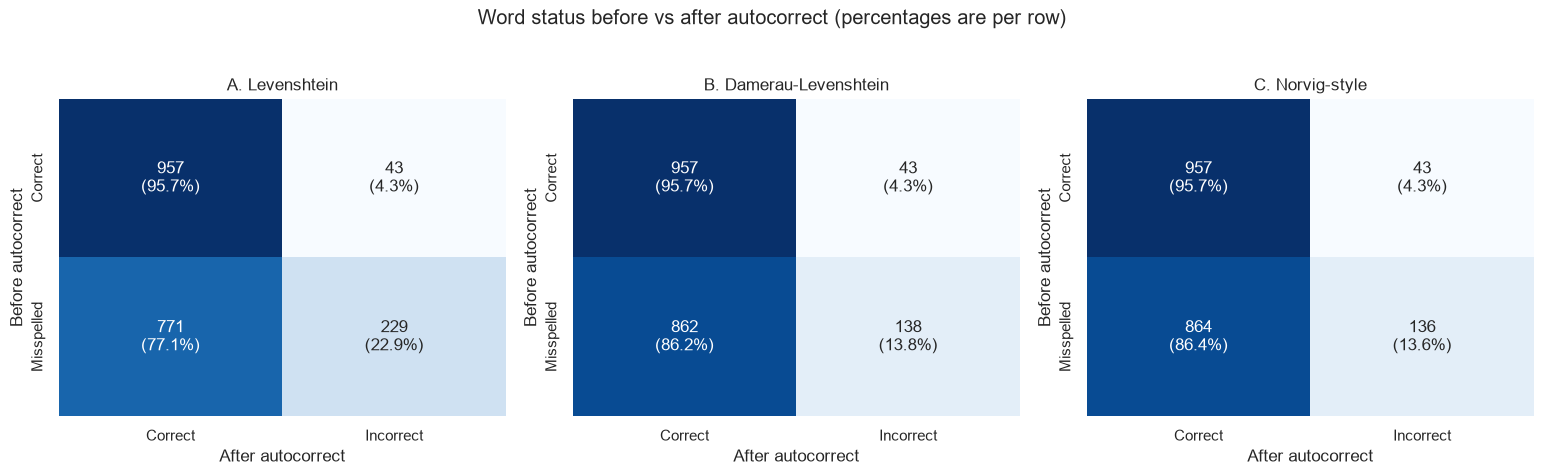

In [21]:
def before_after(items, outputs):
    m = np.zeros((2, 2), dtype=int)               # rows: before (correct, misspelled) | cols: after (correct, incorrect)
    for (typed, intended, _), out in zip(items, outputs):
        before = 0 if typed == intended else 1
        after = 0 if out == intended else 1
        m[before, after] += 1
    return m

n_plots = len(correctors)
fig, axes = plt.subplots(1, n_plots, figsize=(5.2 * n_plots, 4.6))
axes = np.atleast_1d(axes)
for ax, (name, outs) in zip(axes, spell_outputs.items()):
    m = before_after(test_items, outs)
    labels = np.array([[f"{m[i, j]:,}\n({m[i, j] / m[i].sum():.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(m, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Correct", "Incorrect"], yticklabels=["Correct", "Misspelled"])
    ax.set_title(name); ax.set_xlabel("After autocorrect"); ax.set_ylabel("Before autocorrect")
plt.suptitle("Word status before vs after autocorrect (percentages are per row)", y=1.03)
plt.tight_layout(); plt.show()

### 5.5 Precision, recall and accuracy by error type

,TP,FP,FN,TN,Precision,Recall,F1,Accuracy,ms per misspelled word
Approach,,,,,,,,,
A. Levenshtein,771.0,272.0,229.0,957.0,0.739,0.771,0.755,0.864,13.848
B. Damerau-Levenshtein,862.0,181.0,138.0,957.0,0.826,0.862,0.844,0.910,16.962
C. Norvig-style,864.0,179.0,136.0,957.0,0.828,0.864,0.846,0.910,2.391


,deletion,insertion,substitution,transposition
Recall by error type,,,,
A. Levenshtein,0.704,0.996,0.856,0.528
B. Damerau-Levenshtein,0.704,0.996,0.856,0.892
C. Norvig-style,0.708,0.996,0.852,0.900


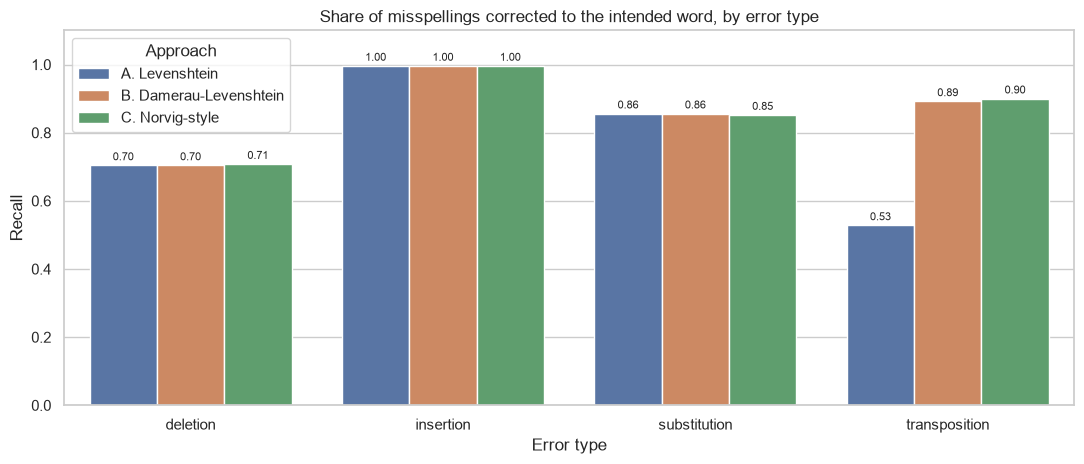

In [22]:
spell_table = pd.DataFrame(spell_results).T
spell_table.index.name = "Approach"
display(spell_table.round(3))

by_kind = {}
for name, outs in spell_outputs.items():
    by_kind[name] = {}
    for kind in KINDS:
        sel = [(o, w) for (t, w, k), o in zip(test_items, outs) if k == kind]
        by_kind[name][kind] = np.mean([o == w for o, w in sel])
by_kind = pd.DataFrame(by_kind).T
display(by_kind.round(3).rename_axis("Recall by error type"))

fig, ax = plt.subplots(figsize=(11, 4.8))
plot_df = by_kind.reset_index().melt(id_vars="index", var_name="Error type", value_name="Recall").rename(columns={"index": "Approach"})
sns.barplot(data=plot_df, x="Error type", y="Recall", hue="Approach", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.1); ax.set_title("Share of misspellings corrected to the intended word, by error type")
plt.tight_layout(); plt.show()

**Reading the results**

*Hand-written test (43 usable words):* Levenshtein corrects **38 (88%)**, Damerau-Levenshtein and the Norvig-style method **42 (98%)**. Levenshtein fails on exactly the swapped-letter typos (`teh`, `wiht`, `tabel`, `tierd`), where it needs two edits and so picks a different, more frequent word (`teh` → *tea*, `tabel` → *mabel*). All three methods fail on `wich`: *with* (substitute one letter) and *which* (insert one letter) are both one edit away, and the more frequent word wins even though the typist meant the other. That is the limit of using only edit distance plus word frequency.

*Synthetic test (1,000 misspellings + 1,000 correct held-out words):*

| Approach | Precision | Recall | F1 | Accuracy | False corrections of correct words | Time per misspelled word |
|---|---|---|---|---|---|---|
| A. Levenshtein | 0.739 | 0.771 | 0.755 | 0.864 | 43 | 12.8 ms |
| B. Damerau-Levenshtein | 0.826 | 0.862 | 0.844 | 0.910 | 43 | 14.0 ms |
| C. Norvig-style | 0.828 | 0.864 | 0.846 | 0.910 | 43 | 2.0 ms |

- **Transpositions are the whole difference between A and B:** recall on swapped-letter typos jumps from 52.8% to 89.2%. For the other error types A and B are identical, as expected, because they only differ in how they count a swap.
- **Error types differ a lot in difficulty.** An *inserted* extra letter is fixed 99.6% of the time (the intended word is almost always the only dictionary word one deletion away). A *dropped* letter is the hardest at about 70%, because many words are one insertion away and the most frequent one is not always the intended one.
- **Precision is lower than recall for every approach.** The cause is the 43 "Correct → Incorrect" cells in the confusion matrices: these are correct words from the held-out text that the dictionary has never seen (58 of the 1,000), and **43 of those 58 (74%) were wrongly "corrected"** into a similar known word. The identical count for all three methods shows it is a dictionary problem, not an algorithm problem. Section 5.6 shows the same effect (`weather` → *feather*, `internet` → *interest*).
- **Damerau-Levenshtein (B) and Norvig-style (C) are essentially equal in accuracy** (they search the same edits; the 2-word difference comes from how ties between 2-edit candidates are resolved), but **C is about 7 times faster** here because it checks a few hundred generated strings against a hash table instead of running a dynamic-programming comparison against every dictionary word of similar length.

### 5.6 When the dictionary is the limit

A dictionary-based corrector can only ever suggest words it has seen. The dictionary has only about two thousand distinct words, so perfectly valid English words outside it get "corrected" into something unrelated.

In [23]:
oov_words = ["internet", "weather", "kittens", "hatters", "tables", "planted", "cheese", "flowers", "computer", "hospital"]
display(pd.DataFrame({"valid English word": oov_words,
                      "in dictionary?": [w in spell_counts for w in oov_words],
                      "Damerau-Levenshtein 'corrects' it to": [correctors["B. Damerau-Levenshtein"](w) for w in oov_words]}).set_index("valid English word"))

,in dictionary?,Damerau-Levenshtein 'corrects' it to
valid English word,,
internet,False,interest
weather,False,feather
kittens,False,kittens
hatters,True,hatters
tables,False,table
planted,False,panted
cheese,False,these
flowers,True,flowers
computer,False,computer


## 6. Performance metrics and algorithm comparison

Summary of both systems. Accuracy metrics were defined in sections 4.3 and 5.3; efficiency is measured as time per query / per misspelled word on this machine (absolute times depend on your hardware; the ratios are what matter).

In [24]:
print("AUTOCOMPLETE (held-out text, top-3 suggestions)")
display(ac_results[["Hit@1", "Hit@3 (= Recall@3)", "Precision@3", "Coverage", "Hit@3 with 2 letters typed",
                    "Fit time (s)", "Stored n-grams", "Time per query (µs)"]].round(3))
print("AUTOCORRECT (1,000 misspellings + 1,000 correct words)")
display(spell_table[["Precision", "Recall", "F1", "Accuracy", "FP", "ms per misspelled word"]].round(3))

AUTOCOMPLETE (held-out text, top-3 suggestions)


,Hit@1,Hit@3 (= Recall@3),Precision@3,Coverage,Hit@3 with 2 letters typed,Fit time (s),Stored n-grams,Time per query (µs)
Model,,,,,,,,
Unigram,0.060,0.122,0.041,1.0,0.665,0.012,2347.0,1.786
Bigram,0.146,0.258,0.086,1.0,0.754,0.032,13883.0,2.169
Trigram + back-off,0.160,0.280,0.093,1.0,0.757,0.163,31174.0,2.503


AUTOCORRECT (1,000 misspellings + 1,000 correct words)


,Precision,Recall,F1,Accuracy,FP,ms per misspelled word
Approach,,,,,,
A. Levenshtein,0.739,0.771,0.755,0.864,272.0,13.848
B. Damerau-Levenshtein,0.826,0.862,0.844,0.910,181.0,16.962
C. Norvig-style,0.828,0.864,0.846,0.910,179.0,2.391


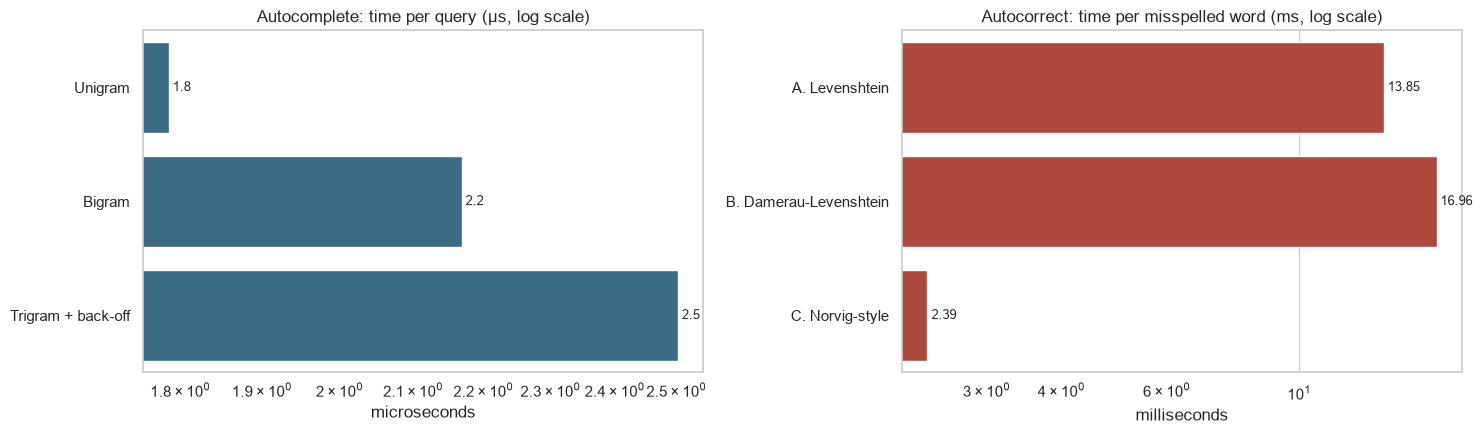

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
lat = ac_results["Time per query (µs)"]
sns.barplot(x=lat.values, y=lat.index, color="#2f6f8f", ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("Autocomplete: time per query (µs, log scale)"); axes[0].set_xlabel("microseconds"); axes[0].set_ylabel("")
for i, v in enumerate(lat.values):
    axes[0].text(v, i, f" {v:,.1f}", va="center", fontsize=9)
ms = spell_table["ms per misspelled word"]
sns.barplot(x=ms.values, y=ms.index, color="#c0392b", ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("Autocorrect: time per misspelled word (ms, log scale)"); axes[1].set_xlabel("milliseconds"); axes[1].set_ylabel("")
for i, v in enumerate(ms.values):
    axes[1].text(v, i, f" {v:,.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Comparison summary**

| | Best accuracy | Cost | Verdict |
|---|---|---|---|
| **Autocomplete** | Trigram + back-off (Hit@3 28.0%, 75.7% with 2 letters typed) | 31k stored n-grams, ~2 µs/query | Bigram gets within ~2 points for less than half the memory; the trigram is worth it as the corpus grows |
| **Autocorrect** | Damerau-Levenshtein and Norvig-style (F1 ≈ 0.84, accuracy 0.91) | A: 12.8 ms, B: 14.0 ms, C: 2.0 ms per word | Counting a transposition as one edit is the single most valuable improvement; candidate generation (C) gives the same accuracy much faster |

**Efficiency trade-offs.** The two scan-based correctors take time proportional to the dictionary size, so they get slower as the dictionary grows. The candidate-generation corrector depends on word length and alphabet instead (a 10-letter word has about 560 strings one edit away, but over 300,000 two edits away), which is why real systems index the dictionary smartly (SymSpell-style precomputed deletes, BK-trees, tries, finite-state transducers) rather than doing either of these naively. Absolute times here come from unoptimised pure Python on a corpus of only 2,347 dictionary words.

**Recommendation.** Use **Damerau-Levenshtein ranking with candidate generation (C)** for correction and a **trigram model with back-off** for prediction. But the most important lesson is that the quality of both is limited by the *data* (a 27k-word corpus), more than by the choice of algorithm.

## 7. Discussion: limitations compared with production systems such as Google Keyboard (Gboard)

**Where this implementation falls short of a production keyboard**

| Area | This notebook | Production keyboards (e.g. Gboard) |
|---|---|---|
| **Language model** | Counts of 1–3 word sequences from one book (~21k training tokens, 2,347 dictionary words). Hit@3 is only 28%. | Neural language models trained on enormous text collections, publicly described by Google as small on-device recurrent networks trained partly with federated learning. They generalise to word sequences they have never seen, which count tables cannot do. |
| **Vocabulary** | Closed: any word outside the dictionary is treated as a typo. **74% of unseen but correct words were wrongly changed**. | Very large, multilingual vocabularies plus subword models, with names, slang, emoji and brand names; the dictionary adapts to the user's own typing. |
| **Error model** | Every edit costs the same, so `wich` cannot tell *with* from *which*. | A statistical model of how people type: a spatial model of where the finger actually touched the screen, neighbouring-key and phonetic errors, per-user error habits. |
| **Context in correction** | Autocorrect ignores the surrounding words. | Candidates are scored by the language model, so the context decides between *with* and *which*, and **real-word errors** (*there/their*, *quiet/quite*) can be caught. This notebook can only detect non-words. |
| **Data and evaluation** | One Victorian novel (dialogue such as "said the Queen"), a random sentence split of the same book, and **synthetic** typos made by my own generator. | Real keystroke logs from millions of users, evaluated with live metrics (accepted suggestions, keystrokes saved, user corrections). |
| **Engineering** | Pure Python, one query at a time, no memory limits. | Hard latency (milliseconds per keystroke) and memory budgets on a phone, optimised data structures such as finite-state transducers, quantised models, and filters for offensive or private content. |
| **Behaviour** | Always outputs the single nearest word. | Decides *whether* to autocorrect at all, shows alternatives, learns from rejected corrections, handles capitalisation, punctuation, gestures and mixed languages. |
| **Privacy** | Not applicable. | Training on personal typing needs on-device learning or federated learning, with privacy protections. |

**Statistical caveats of this study.** The held-out autocomplete test contains about 5,300 queries from one book, and the autocorrect results come from one random seed, so small differences (such as B vs C) should not be over-interpreted. The synthetic typos are single errors per word; real typing often has several in one word.

**How the implementation could be improved**
1. A much larger and more varied corpus (more books, or modern text such as chat messages), and smoothing such as Kneser-Ney for the n-gram model.
2. A small neural language model (LSTM or transformer) as the autocomplete engine, compared against the n-gram baselines.
3. A weighted edit distance in which keyboard-adjacent substitutions and common phonetic confusions are cheaper, combined with word probability in a noisy-channel model: *P(word) × P(typo | word)*.
4. Context-aware correction, using the bigram/trigram model to choose between candidates, and a separate check for real-word errors.
5. A fast index (SymSpell or a BK-tree) in place of dictionary scanning, and an adaptive user dictionary so that unknown words are learned instead of "corrected".